<div style="background: linear-gradient(135deg, #102a43, #1f7a8c); padding: 28px; border-radius: 14px; color: white;">
<h1 style="margin: 0;">Extended Gradient Descent</h1>
<p style="font-size: 17px; margin-bottom: 0;">A visual analysis of the project's multivariable car-price model.</p>
</div>

## What are we demonstrating?

This notebook uses the implementations already defined in `train.py` and `sklearn_train.py`. The custom `Trainer` learns a linear model from mileage, year, engine size, brand, and model. The same prepared inputs are then evaluated with scikit-learn's `LinearRegression` as a reference.

The notebook is intentionally a demonstration layer: data preparation, gradient descent, and scikit-learn training remain in the project source files.

<div style="background: #e8f1f5; border-left: 6px solid #1f7a8c; padding: 14px 18px; border-radius: 8px;">
<b>Goal:</b> compare the project's gradient-descent implementation with the established scikit-learn implementation on the same features and target values.
</div>

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import StrMethodFormatter

from sklearn_train import LinearRegression, main as sklearn_train_main, open_csv as open_sklearn_csv
from train import Model, Trainer, open_csv

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.titlesize": 15, "axes.labelsize": 11})

DATA_PATH = Path("dataset.csv")
REQUIRED_COLUMNS = ["km", "engine_size", "year", "brand", "model", "price"]
data = open_csv(str(DATA_PATH), REQUIRED_COLUMNS)
sklearn_data = open_sklearn_csv(str(DATA_PATH), REQUIRED_COLUMNS)
data.head()

,km,engine_size,year,brand,model,price
0,240000,1.0,2008,Fiat,Punto,3650
1,139800,1.2,2010,Renault,Clio,3800
2,150500,1.4,2011,Fiat,Punto,4400
3,185530,1.6,2009,Volkswagen,Golf,4450
4,176000,1.4,2012,Fiat,Palio,5250


## 1. Explore the training data

In [2]:
numeric_summary = data[["km", "year", "engine_size", "price"]].describe().T
numeric_summary.style.format({"mean": "{:,.1f}", "std": "{:,.1f}", "min": "{:,.1f}", "max": "{:,.1f}"}).background_gradient(cmap="GnBu")

,count,mean,std,min,25%,50%,75%,max
km,24.000000,"101,066.2","52,674.2","22,899.0",65020.500000,83014.500000,140975.000000,"240,000.0"
year,24.000000,"2,014.3",3.0,"2,008.0",2012.750000,2015.000000,2017.000000,"2,018.0"
engine_size,24.000000,1.3,0.2,1.0,1.000000,1.400000,1.600000,1.6
price,24.000000,"6,331.8","1,319.7","3,650.0",5687.500000,6495.000000,7115.000000,"8,290.0"


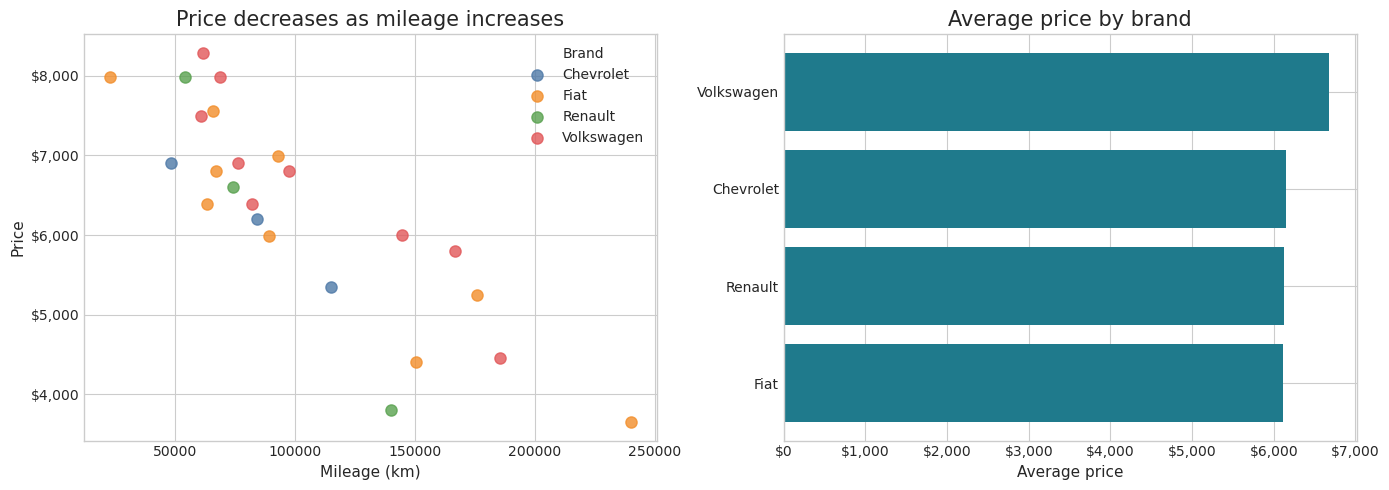

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = {"Fiat": "#f28e2b", "Chevrolet": "#4e79a7", "Renault": "#59a14f", "Volkswagen": "#e15759"}
for brand, group in data.groupby("brand"):
    axes[0].scatter(group["km"], group["price"], s=65, alpha=0.8, label=brand, color=colors.get(brand))
axes[0].set_title("Price decreases as mileage increases")
axes[0].set_xlabel("Mileage (km)")
axes[0].set_ylabel("Price")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[0].legend(title="Brand")

brand_prices = data.groupby("brand", as_index=False)["price"].mean().sort_values("price")
axes[1].barh(brand_prices["brand"], brand_prices["price"], color="#1f7a8c")
axes[1].set_title("Average price by brand")
axes[1].set_xlabel("Average price")
axes[1].xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
plt.tight_layout()
plt.show()

## 2. Train using the project's implementation

`Trainer.gradient_descent()` performs the complete preparation and training workflow from `train.py`. The notebook reuses the trainer's resulting feature matrix, target vector, parameters, and training metadata instead of reproducing the algorithm here.

In [4]:
custom_model = Model()
custom_trainer = Trainer(data=data, model=custom_model)
custom_trainer.gradient_descent()

custom_features = custom_trainer.x_values
custom_target = custom_trainer.y_values
custom_predictions = custom_model.predict(custom_features)
custom_training = custom_trainer.train_resume()

print(f"Rows used by Trainer: {custom_features.shape[0]}")
print(f"Parameters learned: {custom_features.shape[1]}")
print(f"Training epochs: {custom_training['total_epochs']:,}")
print(f"Custom MSE: {custom_training['MSE']:,.2f}")
print(f"Custom RMSE: {custom_training['RMSE']:,.2f}")

Converged after 39000 epochs with loss: 54922.806233
Rows used by Trainer: 24
Parameters learned: 12
Training epochs: 39,000
Custom MSE: 54,922.81
Custom RMSE: 234.36


In [5]:
feature_names = ["intercept"] + custom_training["feature_names"]
feature_matrix = pd.DataFrame(custom_features, columns=feature_names)
feature_matrix.head().style.format("{:,.3f}").background_gradient(cmap="YlGnBu")

,intercept,km,year,engine_size,Fiat,Renault,Volkswagen,Clio,Golf,Palio,Polo,Punto
0,1.000,2.694,-2.165,-1.415,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000
1,1.000,0.751,-1.481,-0.587,0.000,1.000,0.000,1.000,0.000,0.000,0.000,0.000
2,1.000,0.959,-1.140,0.242,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000
3,1.000,1.638,-1.823,1.070,0.000,0.000,1.000,0.000,1.000,0.000,0.000,0.000
4,1.000,1.453,-0.798,0.242,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000


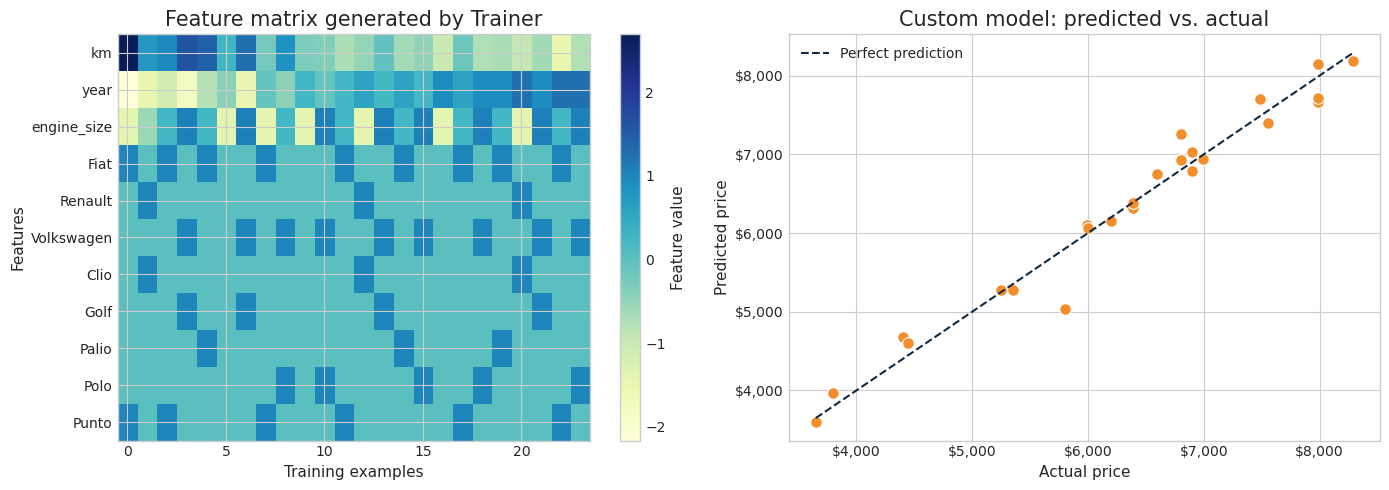

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
image = axes[0].imshow(custom_features[:, 1:].T, aspect="auto", cmap="YlGnBu")
axes[0].set_title("Feature matrix generated by Trainer")
axes[0].set_xlabel("Training examples")
axes[0].set_ylabel("Features")
axes[0].set_yticks(range(len(feature_names) - 1), feature_names[1:])
fig.colorbar(image, ax=axes[0], label="Feature value")

axes[1].scatter(custom_target, custom_predictions, s=70, color="#f28e2b", edgecolor="white", linewidth=0.8)
line_min, line_max = custom_target.min(), custom_target.max()
axes[1].plot([line_min, line_max], [line_min, line_max], linestyle="--", color="#102a43", label="Perfect prediction")
axes[1].set_title("Custom model: predicted vs. actual")
axes[1].set_xlabel("Actual price")
axes[1].set_ylabel("Predicted price")
axes[1].xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[1].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. Compare with `sklearn_train.py`

The project already contains a scikit-learn reference script. The next cell executes its existing `main` function, so the output comes directly from `sklearn_train.py`.

In [7]:
sklearn_train_main([str(DATA_PATH)])

Model trained successfully.
Coefficients: [ 130.27171949 1403.91908343  -78.88699936  291.12877435   72.14636428
  704.88920532   72.14636428  561.8051543   172.6911158   143.08405102
  118.43765855]
MSE:  54922.804994541424
RMSE:  234.3561498969921


In [8]:
sklearn_model = LinearRegression()
sklearn_features = custom_features[:, 1:]
sklearn_model.fit(sklearn_features, custom_target)
sklearn_predictions = sklearn_model.predict(sklearn_features)

comparison = pd.DataFrame({
    "method": ["Project Trainer", "sklearn_train"],
    "MSE": [np.mean((custom_target - custom_predictions) ** 2), np.mean((custom_target - sklearn_predictions) ** 2)],
    "RMSE": [np.sqrt(np.mean((custom_target - custom_predictions) ** 2)), np.sqrt(np.mean((custom_target - sklearn_predictions) ** 2))],
})
comparison.style.format({"MSE": "${:,.2f}", "RMSE": "${:,.2f}"}).background_gradient(cmap="GnBu", subset=["RMSE"])

,method,MSE,RMSE
0,Project Trainer,"$54,922.81",$234.36
1,sklearn_train,"$54,922.80",$234.36


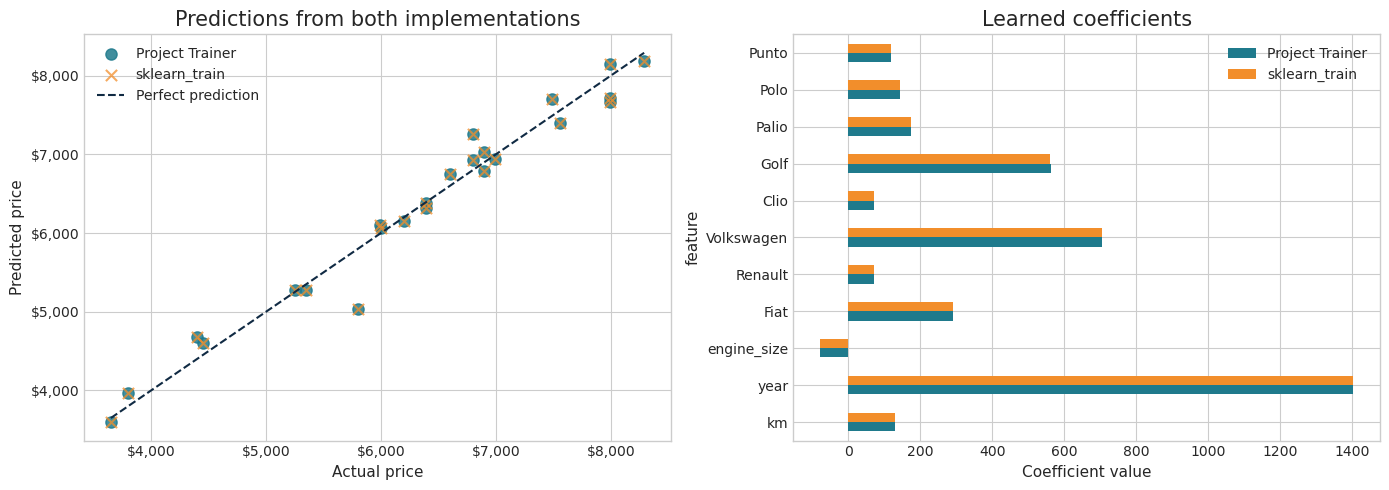

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(custom_target, custom_predictions, s=65, alpha=0.85, color="#1f7a8c", label="Project Trainer")
axes[0].scatter(custom_target, sklearn_predictions, s=65, alpha=0.75, color="#f28e2b", marker="x", label="sklearn_train")
axes[0].plot([line_min, line_max], [line_min, line_max], linestyle="--", color="#102a43", label="Perfect prediction")
axes[0].set_title("Predictions from both implementations")
axes[0].set_xlabel("Actual price")
axes[0].set_ylabel("Predicted price")
axes[0].xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[0].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[0].legend()

coefficient_names = custom_training["feature_names"]
custom_coefficients = custom_model.params[1:]
sklearn_coefficients = sklearn_model.coef_
coefficient_table = pd.DataFrame({
    "feature": coefficient_names,
    "Project Trainer": custom_coefficients,
    "sklearn_train": sklearn_coefficients,
})
coefficient_table.set_index("feature").plot.barh(ax=axes[1], color=["#1f7a8c", "#f28e2b"])
axes[1].set_title("Learned coefficients")
axes[1].set_xlabel("Coefficient value")
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Make a prediction with the trained project model

The custom model can be used through the same feature vector produced by `Trainer`. This keeps the notebook aligned with the feature order used by the implementation.

In [10]:
example_index = 0
example_features = custom_features[example_index:example_index + 1]
example_prediction = custom_model.predict(example_features)[0]
example_actual = custom_target[example_index]

print(f"Example: {data.iloc[example_index]['brand']} {data.iloc[example_index]['model']}")
print(f"Actual price:    ${example_actual:,.2f}")
print(f"Estimated price: ${example_prediction:,.2f}")

Example: Fiat Punto
Actual price:    $3,650.00
Estimated price: $3,598.06
